# Lab 1 v2 — Executable Report: FashionMNIST (`Logistic Regression` vs `MLP`)

**Vai trò của Notebook:** Đây là **Executable Report** trình bày trực quan kết quả thí nghiệm do bộ CLI scripts (`labs/lab1_v2/{train,evaluate,inference}.py`) tạo ra tại `experiments/lab1_v2/`, kết hợp kiểm chứng trực tiếp luồng **Tensor Shape**, **Sanity Check** và **Live Inference**.

> **Lưu ý vận hành:** Toàn bộ quá trình training nặng chạy qua CLI (`python labs/lab1_v2/train.py --run-all`) để có `tqdm` progress bar log, per-run evaluation và tính tái lập sạch; notebook này **không train lại** 12 runs.

## Roadmap & Tài Liệu Liên Quan

| Mục | Nội dung | Nguồn Script / Artifact |
| :---: | :--- | :--- |
| 1 | Cấu hình & Kiểm chứng Tensor Shapes (Logistic vs MLP) | `labs/lab1_v2/config.py`, `src/vibe_scripts/lab1_v2/{logistic,mlp}.py` |
| 2 | Dữ liệu, Manifest SHA-256 & Biểu đồ EDA | `experiments/lab1_v2/eda/` |
| 3 | Sanity Check trực tiếp (Initial Loss + Overfit 1 Batch nhỏ) | `src/vibe_scripts/lab1_v2/trainer.py` |
| 4 | Bảng kết quả Chuỗi Thí Nghiệm (Per-Run Val Eval) | `experiments/lab1_v2/ablation/ablation_summary.json` |
| 5 | Đánh giá Final Test (10k), Curves, Confusion Matrix & Error Analysis | `experiments/lab1_v2/evaluation/`, `experiments/lab1_v2/figures/` |
| 6 | Live Inference Demo & Latency Benchmark | `src/vibe_scripts/lab1_v2/inference.py` |

- Đặc tả Pipeline: [`docs/pipelines/modeling.md`](docs/pipelines/modeling.md)
- Đặc tả Models: [`docs/models/logistic_regression.md`](docs/models/logistic_regression.md) · [`docs/models/mlp.md`](docs/models/mlp.md)
- Báo cáo Dữ liệu & EDA: [`docs/eda_report.md`](docs/eda_report.md)
- Báo cáo Thí nghiệm & Training Diagnostics (Layer 4, 7): [`docs/experiment_report.md`](docs/experiment_report.md)
- Báo cáo Đánh giá Val/Model Selection, Final Test (10k) & Error Analysis (Layer 8–10): [`docs/evaluation_report.md`](docs/evaluation_report.md)

In [1]:
import json
import sys
from pathlib import Path

import torch
from IPython.display import Image as IPyImage, Markdown, display

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "src").exists() and REPO_ROOT.parent != REPO_ROOT:
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import labs.lab1_v2.config as cfg
from src.vibe_scripts.lab1_v2 import (
    FashionPredictor,
    build_model,
    count_parameters,
    prepare_fashion_mnist,
    run_sanity_checks,
    set_global_seed,
)

set_global_seed(cfg.SEED)
print(f"Repo Root : {REPO_ROOT}")
print(f"Device    : {cfg.DEVICE} | Seed: {cfg.SEED}")
print(f"Exp Dir   : {cfg.EXPERIMENT_DIR}")

# Kiểm chứng trực tiếp Tensor Shape qua cả 2 kiến trúc
dummy = torch.randn(8, *cfg.IMAGE_SHAPE)
for kind, hdims in [("logistic", ()), ("mlp", cfg.DEFAULT_HIDDEN_DIMS)]:
    m = build_model(kind, input_shape=cfg.IMAGE_SHAPE, num_classes=cfg.NUM_CLASSES, hidden_dims=hdims)
    print(f"\n=== {kind.upper()} ({count_parameters(m):,} params) ===")
    for step in m.trace_shapes(dummy):
        print(f"  {step['layer']:<28} -> shape={step['shape']} ({step['dtype']})")

Repo Root : D:\notworLe\Desktop\gitvanhub\Deeplearning-UTH
Device    : cuda | Seed: 248
Exp Dir   : D:\notworLe\Desktop\gitvanhub\Deeplearning-UTH\experiments\lab1_v2

=== LOGISTIC (7,850 params) ===
  Input                        -> shape=[8, 1, 28, 28] (torch.float32)
  Flatten(1)                   -> shape=[8, 784] (torch.float32)
  Linear(784, 10)              -> shape=[8, 10] (torch.float32)

=== MLP (235,146 params) ===
  Input                        -> shape=[8, 1, 28, 28] (torch.float32)
  Flatten(1)                   -> shape=[8, 784] (torch.float32)
  backbone[0]: Linear          -> shape=[8, 256] (torch.float32)
  backbone[1]: ReLU            -> shape=[8, 256] (torch.float32)
  backbone[2]: Dropout         -> shape=[8, 256] (torch.float32)
  backbone[3]: Linear          -> shape=[8, 128] (torch.float32)
  backbone[4]: ReLU            -> shape=[8, 128] (torch.float32)
  backbone[5]: Dropout         -> shape=[8, 128] (torch.float32)
  Linear(128, 10)              -> shape=[8, 

6.1 Collection : {'raw_train': 60000, 'raw_test': 10000, 'total': 70000} | manifest_ok= True
6.2 Cleaning   : {'train_intra_duplicates': 0, 'val_intra_duplicates': 0, 'test_intra_duplicates': 0, 'cross_train_val_unique_shared': 0, 'cross_train_val_val_samples_affected': 0, 'cross_trainraw_test_unique_shared': 0, 'cross_trainraw_test_test_samples_affected': 0, 'conflicting_label_duplicate_groups': 0, 'conflicting_label_examples': []} | corrupt= 0
6.3 Splits     : {'train': 55000, 'val': 5000, 'test': 10000, 'total': 70000}
Train Pixel    : {'mean': 0.2862969934940338, 'std': 0.35322320461273193, 'min': 0.0, 'max': 1.0, 'zero_pixel_ratio': 0.5020043253898621}
Outliers (IQR) : {'q1_mean_intensity': 0.18575431406497955, 'q3_mean_intensity': 0.38227418065071106, 'iqr': 0.1965198665857315, 'low_fence': -0.1090254858136177, 'high_fence': 0.6770539805293083, 'low_intensity_outliers': 0, 'high_intensity_outliers': 23, 'min_image_mean': 0.019387755542993546, 'max_image_mean': 0.7522358894348145}

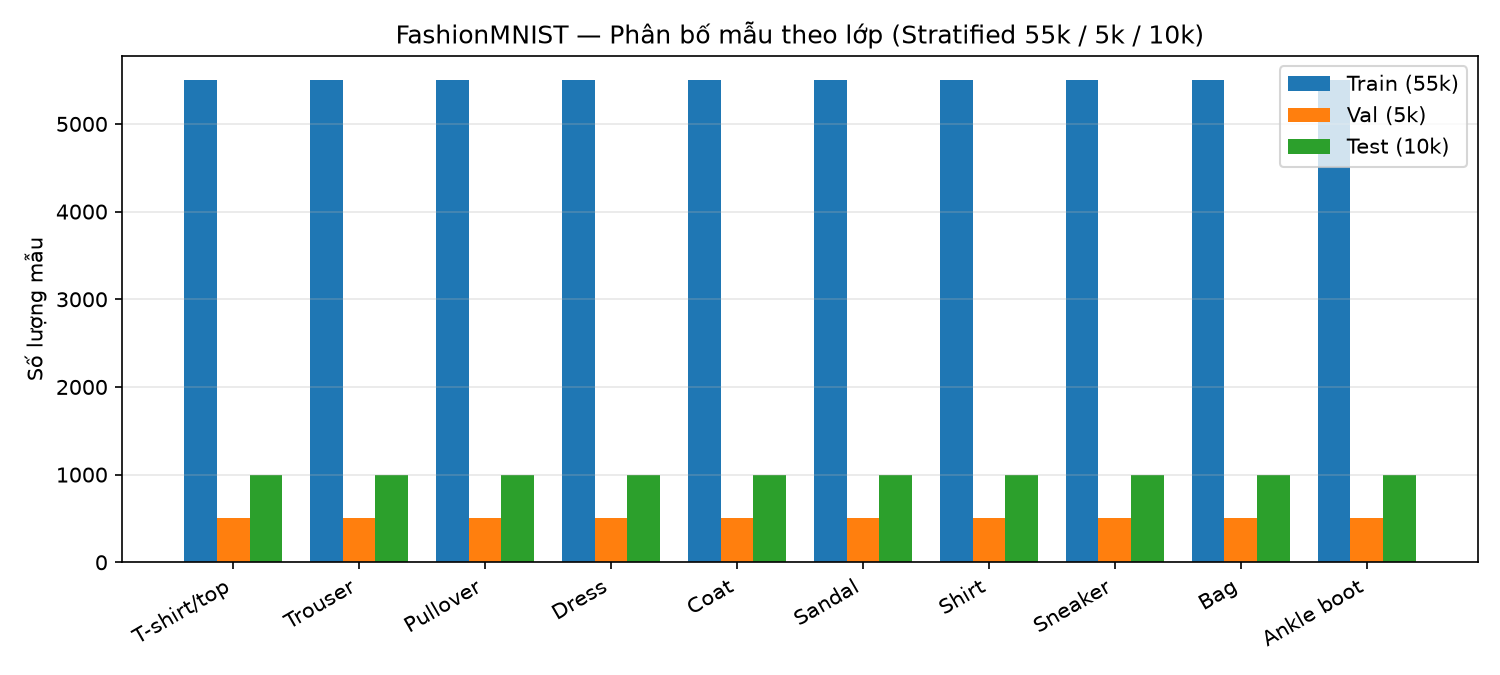

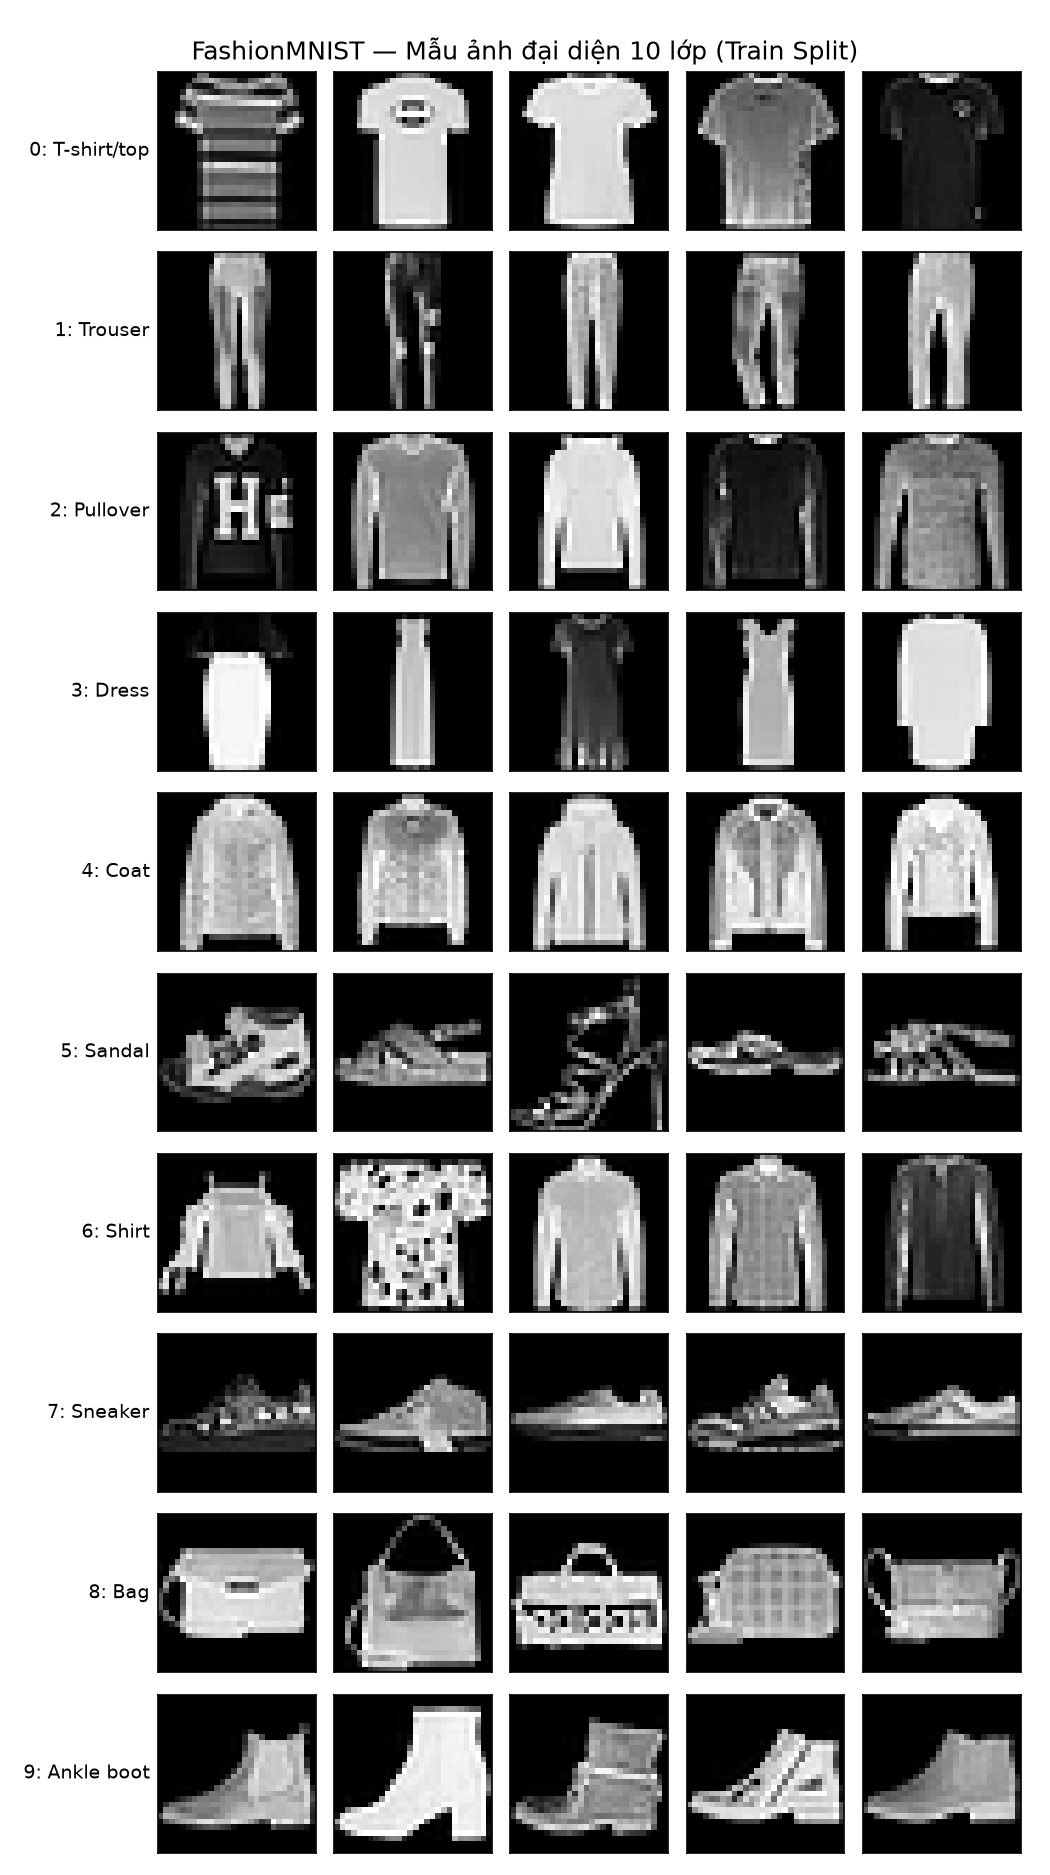

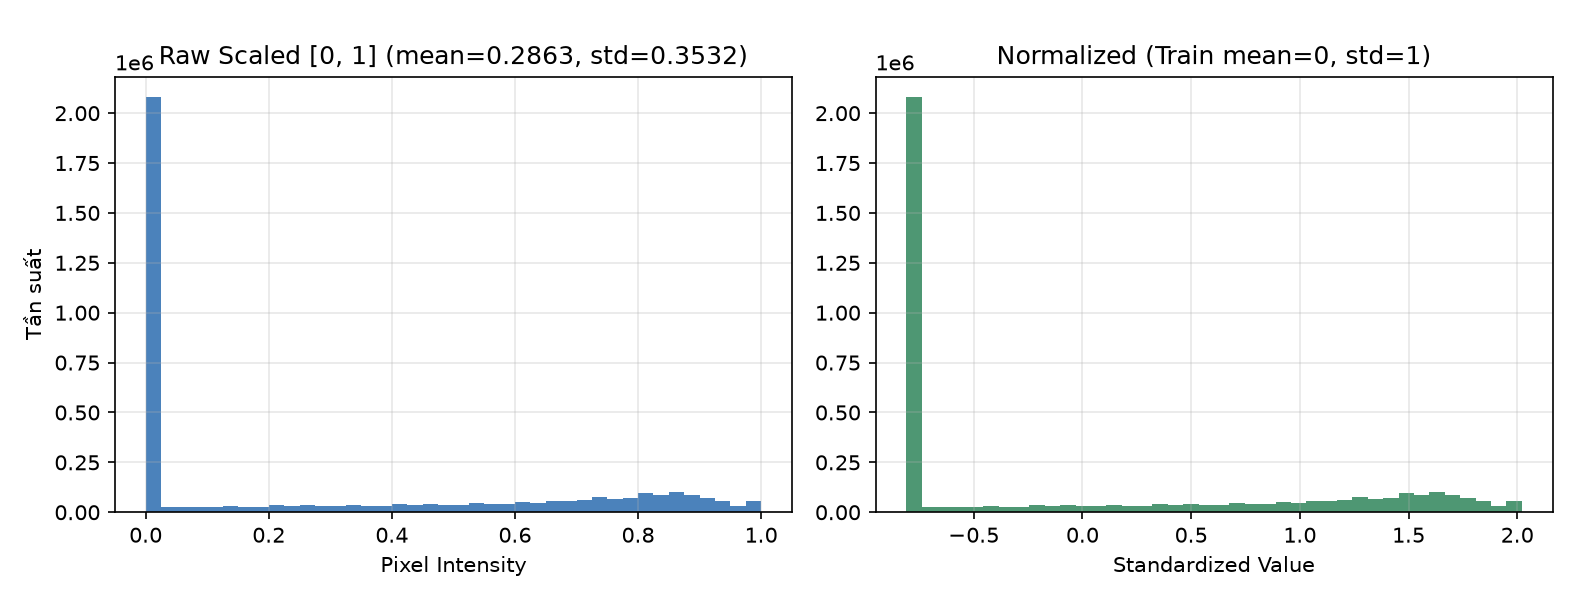

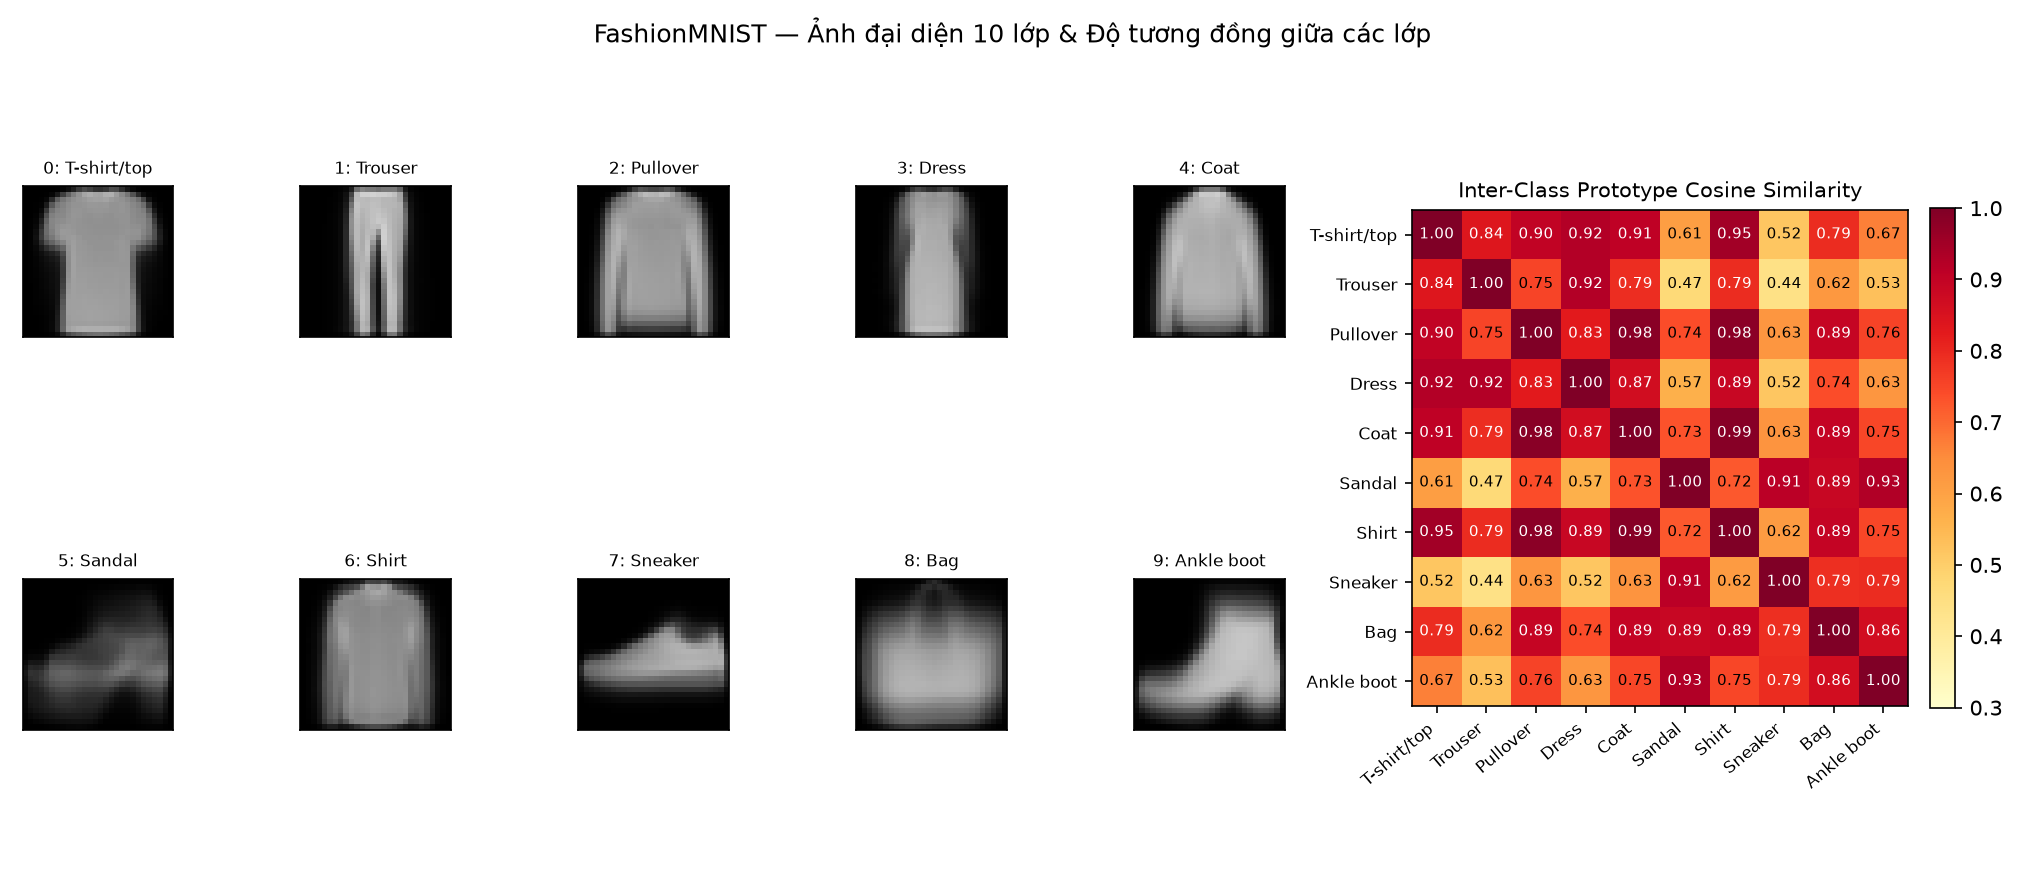

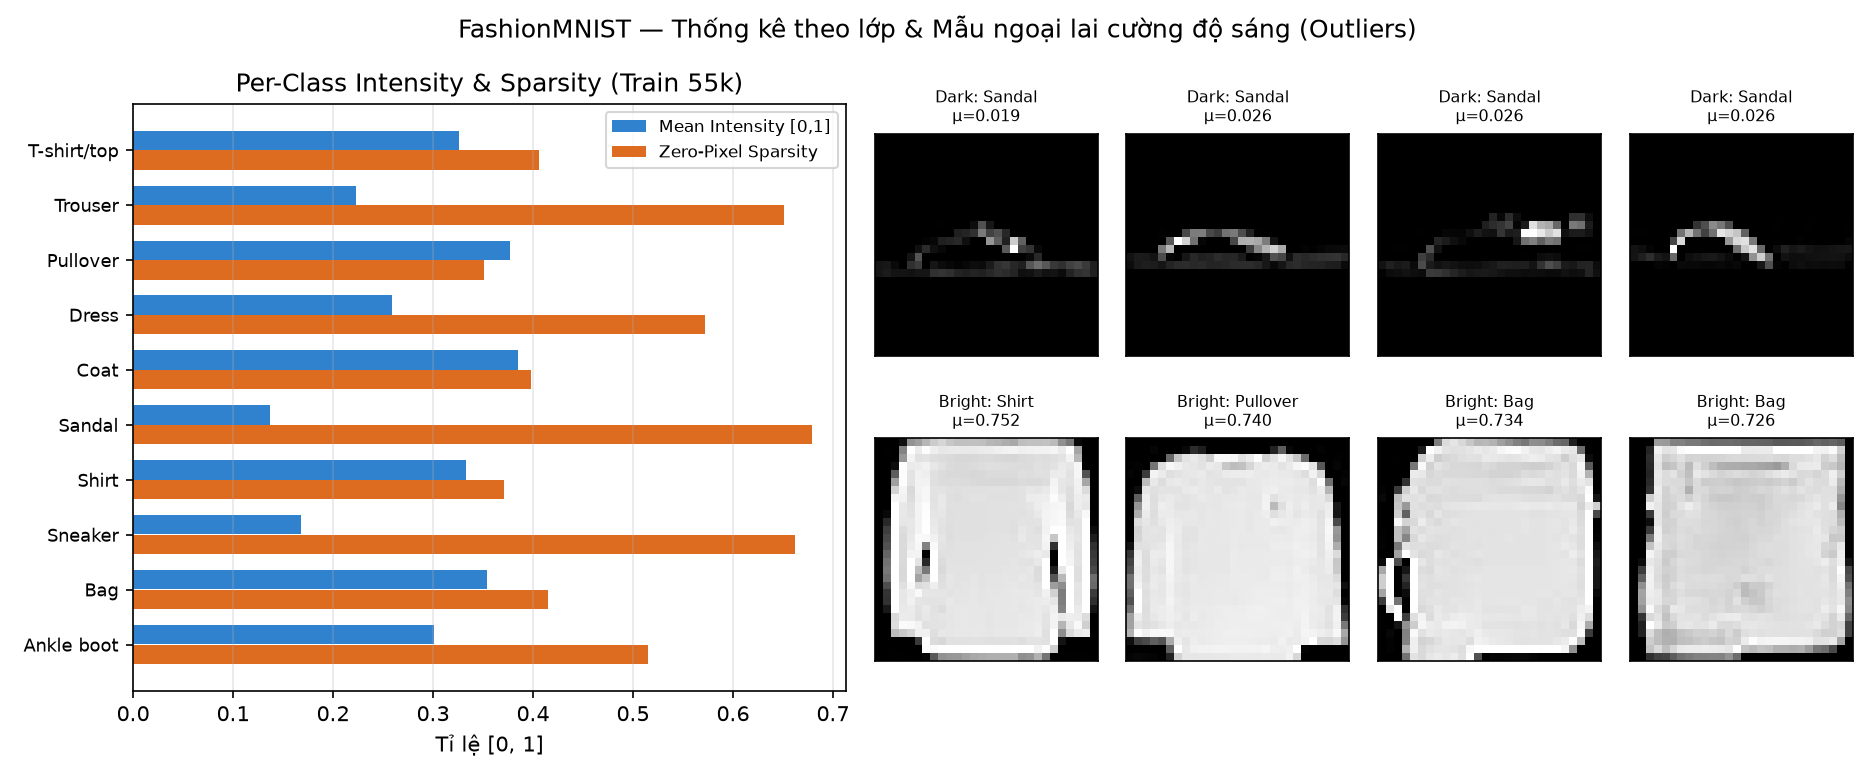

In [2]:
eda_json = cfg.EDA_DIR / "eda_summary.json"
col_json = cfg.EDA_DIR / "collection_report.json"
cln_json = cfg.EDA_DIR / "cleaning_report.json"
if not eda_json.exists():
    print("Chưa có EDA artifacts. Hãy chạy: python labs/lab1_v2/prepare_data.py")
else:
    if col_json.exists():
        col = json.loads(col_json.read_text(encoding="utf-8"))
        print("6.1 Collection :", col["records"], "| manifest_ok=", col["manifest_integrity"]["verified"])
    if cln_json.exists():
        cln = json.loads(cln_json.read_text(encoding="utf-8"))
        print("6.2 Cleaning   :", cln["duplicate_audit"], "| corrupt=", cln["clean_status"]["corrupt_or_invalid_total"])
    eda = json.loads(eda_json.read_text(encoding="utf-8"))
    print("6.3 Splits     :", eda["splits"])
    print("Train Pixel    :", eda["train_pixel_stats"])
    print("Outliers (IQR) :", eda["outlier_analysis_iqr"])
    print("Top Sim Pairs  :", eda["prototype_cosine_similarity"]["top_similar_pairs"][:3])
    for key in [
        "class_distribution_plot",
        "sample_grid_plot",
        "pixel_distribution_plot",
        "prototypes_similarity_plot",
        "outliers_class_stats_plot",
    ]:
        p = Path(eda["artifacts"][key])
        if p.exists():
            display(IPyImage(filename=str(p)))

In [3]:
# Kiểm chứng nhanh Sanity Check trên 1 batch 32 mẫu (chạy < 1s, không ghi artifact)
bundle = prepare_fashion_mnist(
    data_root=cfg.DATA_PATH,
    batch_size=cfg.SANITY_BATCH_SIZE,
    val_size=cfg.VAL_SIZE,
    seed=cfg.SEED,
    num_workers=cfg.WOKER,
    class_names=cfg.CLASS_NAMES,
    verify_manifest=True,
)
sample_x, sample_y = next(iter(bundle.train_loader))
sanity_mlp = build_model(
    "mlp",
    input_shape=cfg.IMAGE_SHAPE,
    num_classes=cfg.NUM_CLASSES,
    hidden_dims=cfg.DEFAULT_HIDDEN_DIMS,
    dropout=0.0,
)
sanity = run_sanity_checks(
    model=sanity_mlp,
    sample_batch=sample_x,
    sample_targets=sample_y,
    device=cfg.DEVICE,
    max_steps=cfg.SANITY_MAX_STEPS,
    target_acc=cfg.SANITY_OVERFIT_ACC,
)
print(json.dumps(sanity, indent=2))

{
  "initial_loss": 2.3432846069335938,
  "expected_random_loss": 2.302585092994046,
  "initial_loss_ok": true,
  "overfit_final_loss": 0.06376206129789352,
  "overfit_final_acc": 0.96875,
  "overfit_steps": 9,
  "overfit_passed": true
}


Completed: 12/12 | Stopped early: False (completed_all_planned_runs)
Baseline: baseline_logistic | Winning MLP: mlp_default

Run ID             Axis             Params BestEp  ValLoss  ValAcc%   ValF1%  Time(s)
-------------------------------------------------------------------------------------
baseline_logistic  baseline          7,850     11   0.4241    85.58    85.49     33.0
mlp_default        anchor          235,146     14   0.2955    89.74    89.62     52.6
mlp_h128           hidden_dims     101,770     10   0.3040    88.76    88.70     44.8
mlp_h512_256_128   hidden_dims     567,434     14   0.3078    89.40    89.35     60.5
mlp_lr1e4          learning_rate   235,146     18   0.2866    89.02    89.07     53.3
mlp_lr1e2          learning_rate   235,146     19   0.4687    83.80    83.87     52.7
mlp_opt_sgd        optimizer       235,146     20   0.3204    88.02    88.00     46.6
mlp_opt_adamw      optimizer       235,146      9   0.2958    88.76    88.68     51.9
mlp_bs32       

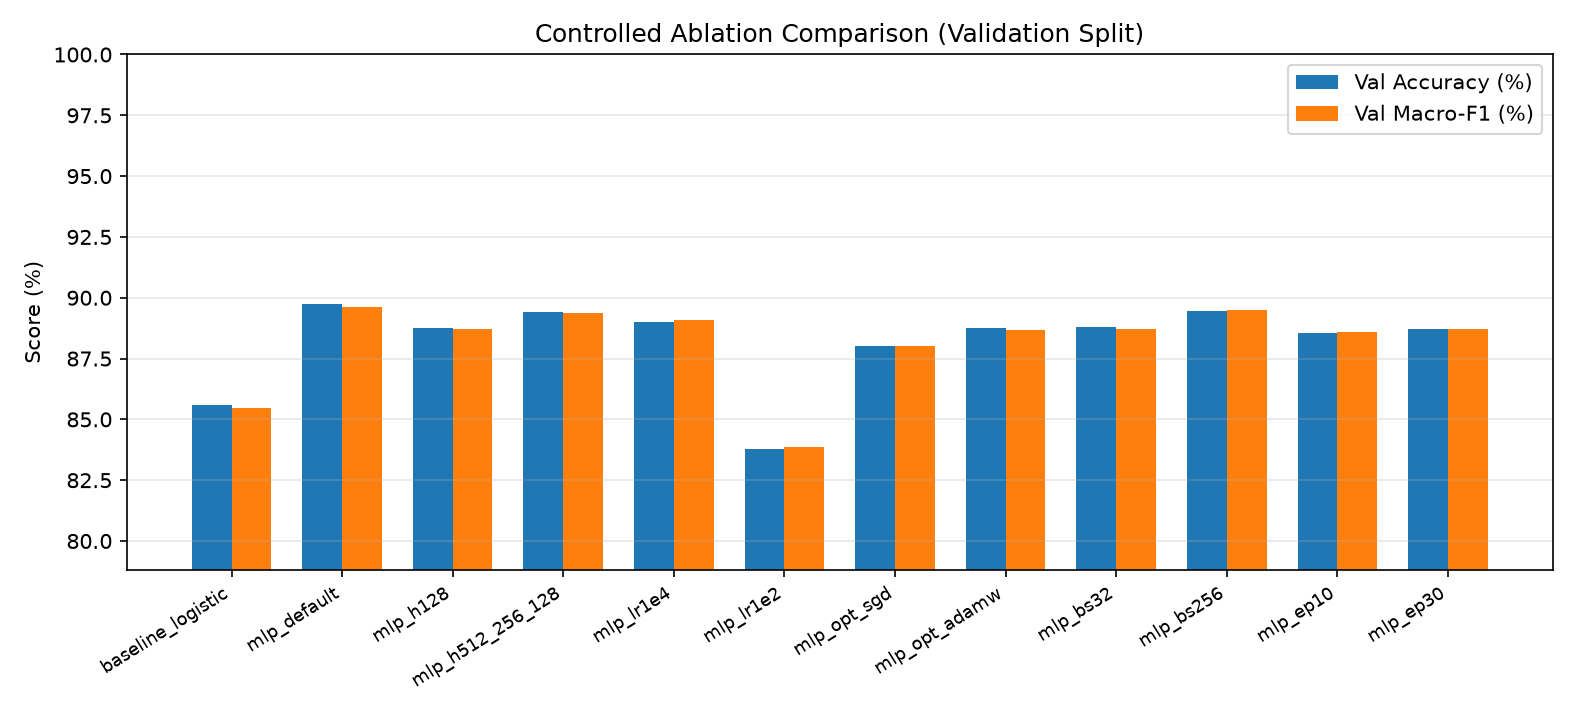

In [4]:
ablation_json = cfg.ABLATION_DIR / "ablation_summary.json"
if not ablation_json.exists():
    print("Chưa có kết quả training. Hãy chạy: python labs/lab1_v2/train.py --run-all")
else:
    abl = json.loads(ablation_json.read_text(encoding="utf-8"))
    print(
        f"Completed: {abl['completed_runs']}/{abl['total_planned_runs']} | "
        f"Stopped early: {abl['stopped_early']} ({abl['stop_reason']})"
    )
    print(f"Baseline: {abl['baseline_run_id']} | Winning MLP: {abl['winning_mlp_run_id']}\n")
    header = f"{'Run ID':<18} {'Axis':<14} {'Params':>8} {'BestEp':>6} {'ValLoss':>8} {'ValAcc%':>8} {'ValF1%':>8} {'Time(s)':>8}"
    print(header)
    print("-" * len(header))
    for r in abl["runs"]:
        print(
            f"{r['run_id']:<18} {r['axis']:<14} {r['num_parameters']:>8,} {r['best_epoch']:>6} "
            f"{r['val_loss']:>8.4f} {r['val_acc']*100:>8.2f} {r['val_macro_f1']*100:>8.2f} {r['train_time_sec']:>8.1f}"
        )
    abl_plot = cfg.FIGURES_DIR / "ablation_comparison.png"
    if abl_plot.exists():
        display(IPyImage(filename=str(abl_plot)))

### 4.1 `baseline_logistic` (Baseline)
- **Best Ep 11:** `val_loss=0.4241`, `val_acc=85.58%`, `val_f1=85.49%`, `gap(tr-va)=+0.50 pp` | **Last Ep 20:** `val_loss=0.4659`, `gap=+2.43 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/baseline_logistic/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/baseline_logistic/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/baseline_logistic/eval/eval_metrics.json)

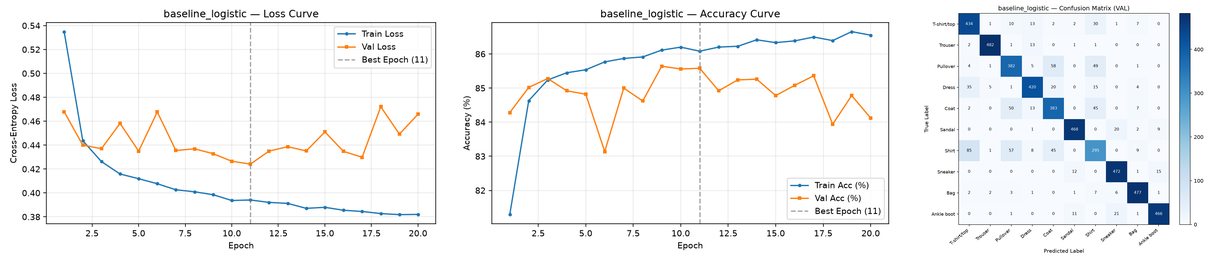

### 4.2 `mlp_default` (MLP Anchor)
- **Best Ep 14:** `val_loss=0.2955`, `val_acc=89.74%`, `val_f1=89.62%`, `gap(tr-va)=+1.10 pp` | **Last Ep 20:** `val_loss=0.3117`, `gap=+2.34 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_default/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_default/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_default/eval/eval_metrics.json)

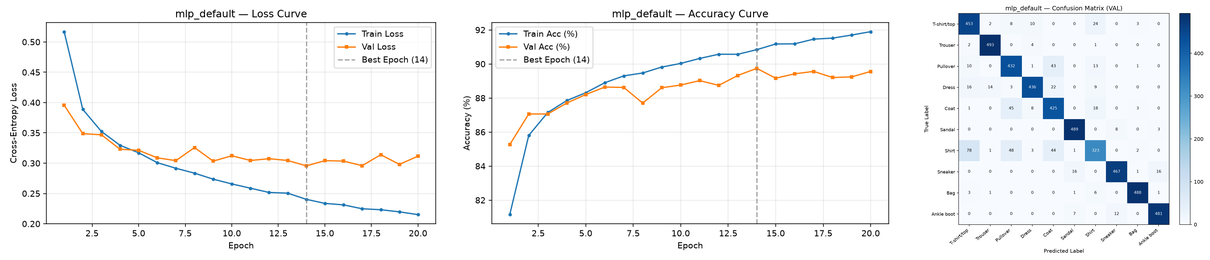

### 4.3 `mlp_h128` (Ablation: Hidden Dims)
- **Best Ep 10:** `val_loss=0.3040`, `val_acc=88.76%`, `val_f1=88.70%`, `gap(tr-va)=+1.16 pp` | **Last Ep 20:** `val_loss=0.3174`, `gap=+2.50 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_h128/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_h128/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_h128/eval/eval_metrics.json)

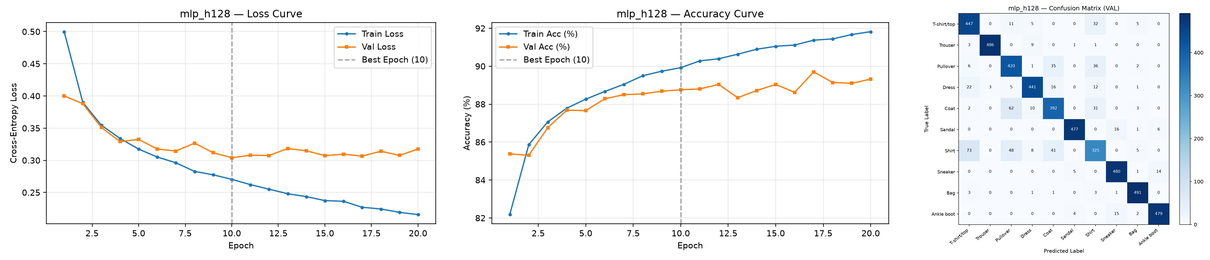

### 4.4 `mlp_h512_256_128` (Ablation: Hidden Dims)
- **Best Ep 14:** `val_loss=0.3078`, `val_acc=89.40%`, `val_f1=89.35%`, `gap(tr-va)=+1.42 pp` | **Last Ep 20:** `val_loss=0.3283`, `gap=+2.98 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_h512_256_128/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_h512_256_128/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_h512_256_128/eval/eval_metrics.json)

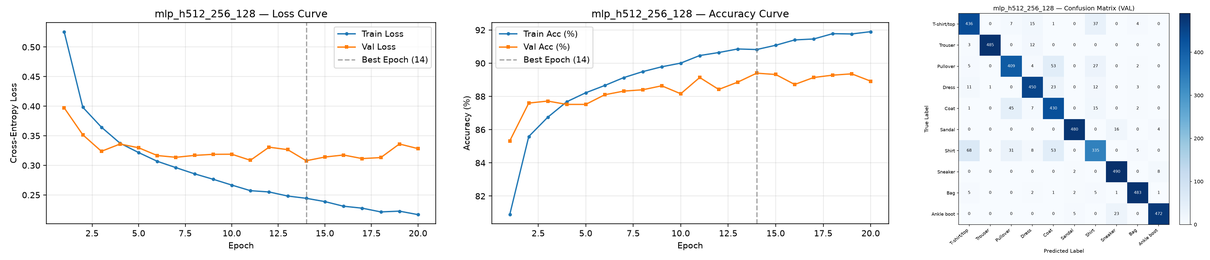

### 4.5 `mlp_lr1e4` (Ablation: Learning Rate)
- **Best Ep 18:** `val_loss=0.2866`, `val_acc=89.02%`, `val_f1=89.07%`, `gap(tr-va)=+1.61 pp` | **Last Ep 20:** `val_loss=0.2896`, `gap=+1.77 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_lr1e4/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_lr1e4/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_lr1e4/eval/eval_metrics.json)

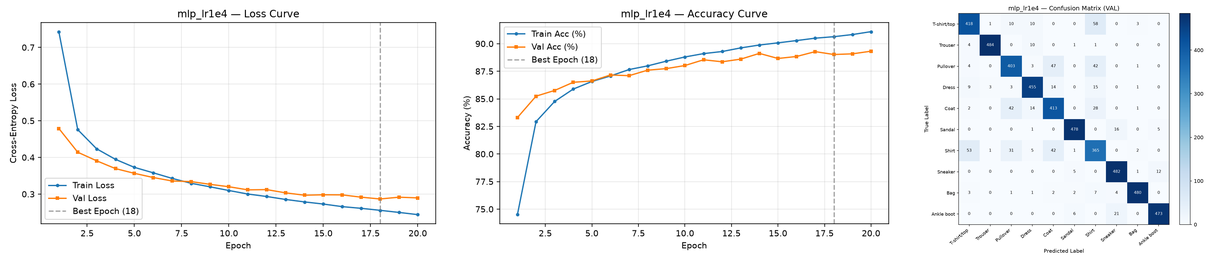

### 4.6 `mlp_lr1e2` (Ablation: Learning Rate)
- **Best Ep 19:** `val_loss=0.4687`, `val_acc=83.80%`, `val_f1=83.87%`, `gap(tr-va)=-2.90 pp` | **Last Ep 20:** `val_loss=0.4806`, `gap=-4.53 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_lr1e2/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_lr1e2/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_lr1e2/eval/eval_metrics.json)

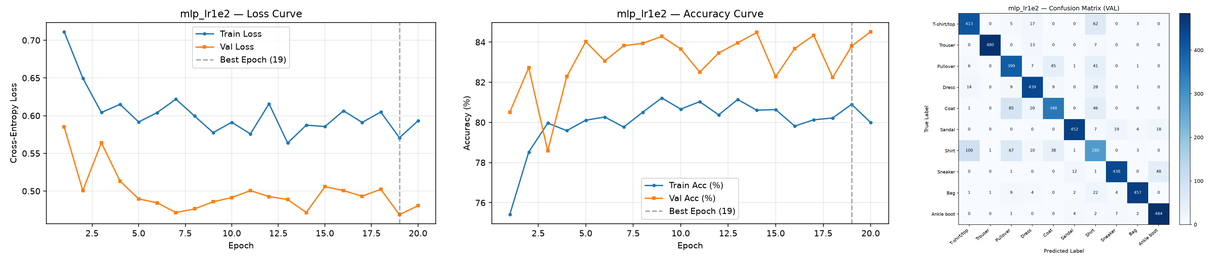

### 4.7 `mlp_opt_sgd` (Ablation: Optimizer)
- **Best Ep 20:** `val_loss=0.3204`, `val_acc=88.02%`, `val_f1=88.00%`, `gap(tr-va)=+1.00 pp` | **Last Ep 20:** `val_loss=0.3204`, `gap=+1.00 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_opt_sgd/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_opt_sgd/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_opt_sgd/eval/eval_metrics.json)

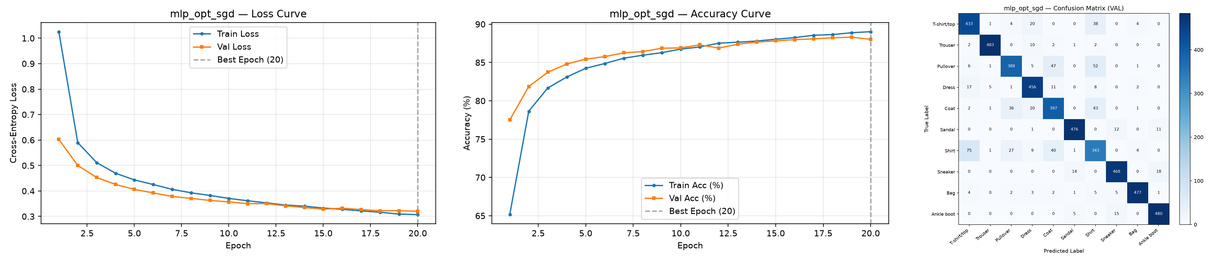

### 4.8 `mlp_opt_adamw` (Ablation: Optimizer)
- **Best Ep 9:** `val_loss=0.2958`, `val_acc=88.76%`, `val_f1=88.68%`, `gap(tr-va)=+0.94 pp` | **Last Ep 20:** `val_loss=0.3016`, `gap=+2.80 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_opt_adamw/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_opt_adamw/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_opt_adamw/eval/eval_metrics.json)

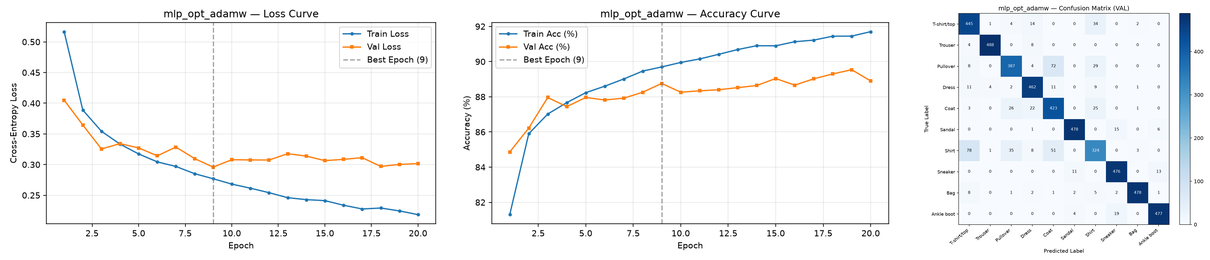

### 4.9 `mlp_bs32` (Ablation: Batch Size)
- **Best Ep 12:** `val_loss=0.3022`, `val_acc=88.80%`, `val_f1=88.72%`, `gap(tr-va)=+1.26 pp` | **Last Ep 20:** `val_loss=0.3224`, `gap=+1.87 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_bs32/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_bs32/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_bs32/eval/eval_metrics.json)

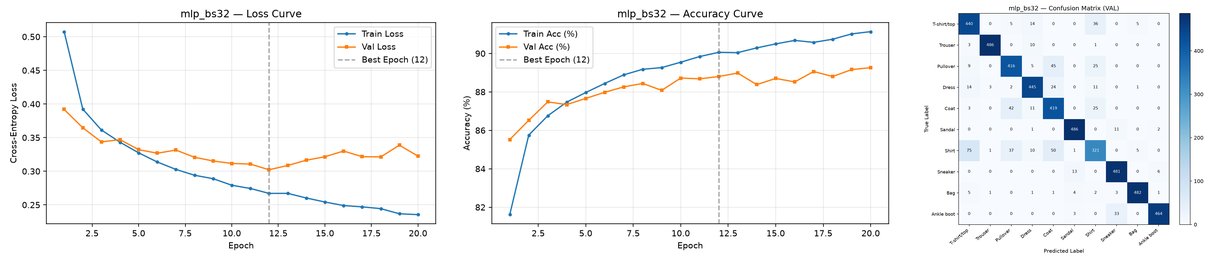

### 4.10 `mlp_bs256` (Ablation: Batch Size)
- **Best Ep 12:** `val_loss=0.2887`, `val_acc=89.46%`, `val_f1=89.51%`, `gap(tr-va)=+1.58 pp` | **Last Ep 20:** `val_loss=0.2934`, `gap=+2.58 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_bs256/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_bs256/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_bs256/eval/eval_metrics.json)

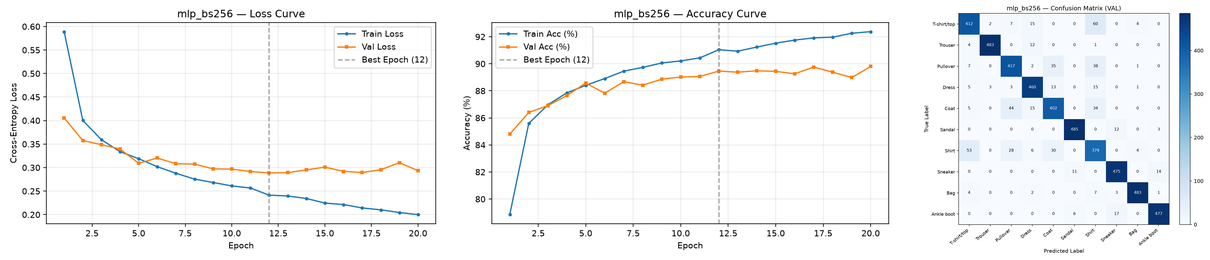

### 4.11 `mlp_ep10` (Ablation: Epoch)
- **Best Ep 10:** `val_loss=0.3130`, `val_acc=88.54%`, `val_f1=88.60%`, `gap(tr-va)=+1.20 pp` | **Last Ep 10:** `val_loss=0.3130`, `gap=+1.20 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_ep10/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_ep10/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_ep10/eval/eval_metrics.json)

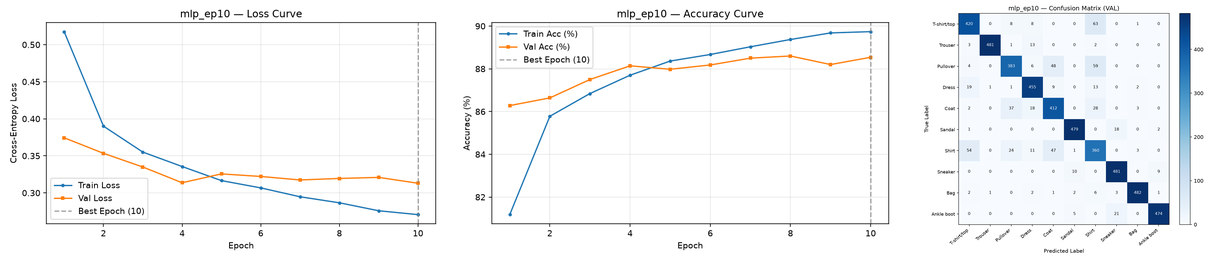

### 4.12 `mlp_ep30` (Ablation: Epoch)
- **Best Ep 8:** `val_loss=0.3043`, `val_acc=88.70%`, `val_f1=88.71%`, `gap(tr-va)=+0.73 pp` | **Last Ep 30:** `val_loss=0.3264`, `gap=+3.08 pp`
- **Logs:** [`history.csv`](../../experiments/lab1_v2/runs/mlp_ep30/historys/history.csv) · [`history.json`](../../experiments/lab1_v2/runs/mlp_ep30/historys/history.json) · [`eval_metrics.json`](../../experiments/lab1_v2/runs/mlp_ep30/eval/eval_metrics.json)

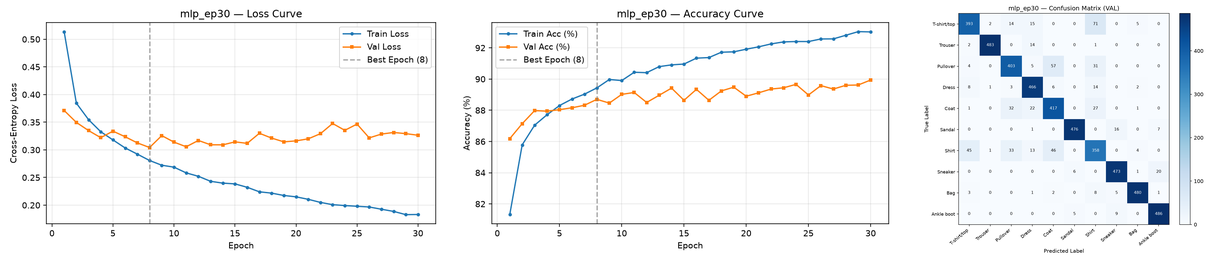

In [5]:
# Phân tích trực quan từng cấu hình: Loss Curve | Accuracy Curve | Confusion Matrix & History Logs
if ablation_json.exists():
    from PIL import Image as PILImage
    import io as _io

    abl = json.loads(ablation_json.read_text(encoding="utf-8"))
    for idx, r in enumerate(abl["runs"], start=1):
        rid = r["run_id"]
        run_rel = f"../../experiments/lab1_v2/runs/{rid}"
        run_dir = cfg.RUNS_DIR / rid
        hist_json = run_dir / "historys" / "history.json"
        h = json.loads(hist_json.read_text(encoding="utf-8"))
        eps = h["epochs"]
        b_row = eps[h["best_epoch"] - 1]
        l_row = eps[-1]
        gap_b = (b_row["train_acc"] - b_row["val_acc"]) * 100
        gap_l = (l_row["train_acc"] - l_row["val_acc"]) * 100

        display(
            Markdown(
                f"### 4.{idx} `{rid}` ({r['group']})\n"
                f"- **Best Ep {h['best_epoch']}:** `val_loss={b_row['val_loss']:.4f}`, `val_acc={b_row['val_acc']*100:.2f}%`, `val_f1={r['val_macro_f1']*100:.2f}%`, `gap(tr-va)={gap_b:+.2f} pp` | "
                f"**Last Ep {l_row['epoch']}:** `val_loss={l_row['val_loss']:.4f}`, `gap={gap_l:+.2f} pp`\n"
                f"- **Logs:** [`history.csv`]({run_rel}/historys/history.csv) · [`history.json`]({run_rel}/historys/history.json) · [`eval_metrics.json`]({run_rel}/eval/eval_metrics.json)"
            )
        )

        # Ghép gọn 3 ảnh (Loss | Accuracy | Confusion Matrix) thành 1 hàng ngang
        p_loss = run_dir / "eval" / "loss_curve.png"
        p_acc = run_dir / "eval" / "accuracy_curve.png"
        p_cm = run_dir / "eval" / "confusion_matrix.png"
        if p_loss.exists() and p_acc.exists() and p_cm.exists():
            imgs = [PILImage.open(p).convert("RGB") for p in (p_loss, p_acc, p_cm)]
            target_h = 260
            resized = [im.resize((int(im.width * target_h / im.height), target_h), PILImage.Resampling.LANCZOS) for im in imgs]
            total_w = sum(im.width for im in resized) + 16
            canvas = PILImage.new("RGB", (total_w, target_h), (255, 255, 255))
            x_off = 0
            for im in resized:
                canvas.paste(im, (x_off, 0))
                x_off += im.width + 8
            buf_img = _io.BytesIO()
            canvas.save(buf_img, format="PNG", optimize=True)
            display(IPyImage(data=buf_img.getvalue()))


=== FINAL TEST COMPARISON (10,000 samples) ===
baseline_logistic  | params=  7,850 | test_loss=0.4473 | test_acc=84.35% | macro_f1=84.21% | save_load_ok=True
mlp_default        | params=235,146 | test_loss=0.3362 | test_acc=88.79% | macro_f1=88.68% | save_load_ok=True

MLP Gain vs Baseline: Acc +4.44 pp | Macro-F1 +4.47 pp | Loss -0.1110

Top-5 Best MLP Confusions: [{'true_class': 'Shirt', 'pred_class': 'T-shirt/top', 'count': 158}, {'true_class': 'Shirt', 'pred_class': 'Pullover', 'count': 112}, {'true_class': 'Coat', 'pred_class': 'Pullover', 'count': 96}, {'true_class': 'Pullover', 'pred_class': 'Coat', 'count': 86}, {'true_class': 'T-shirt/top', 'pred_class': 'Shirt', 'count': 75}]


### loss_curves

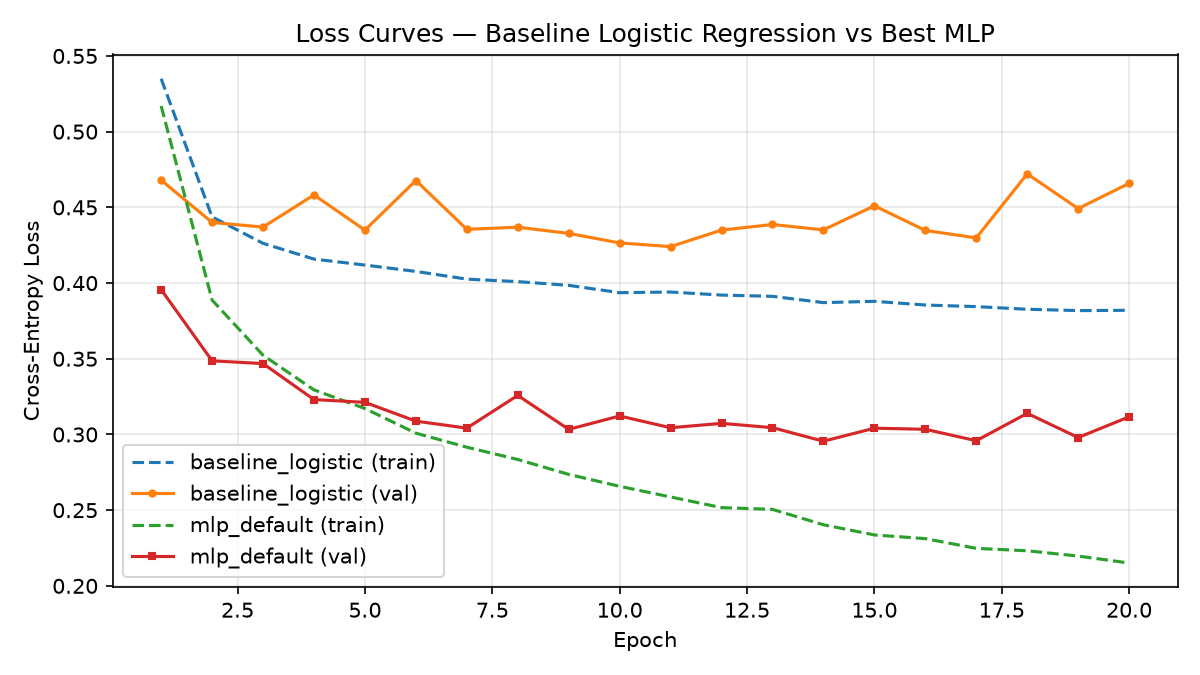

### accuracy_curves

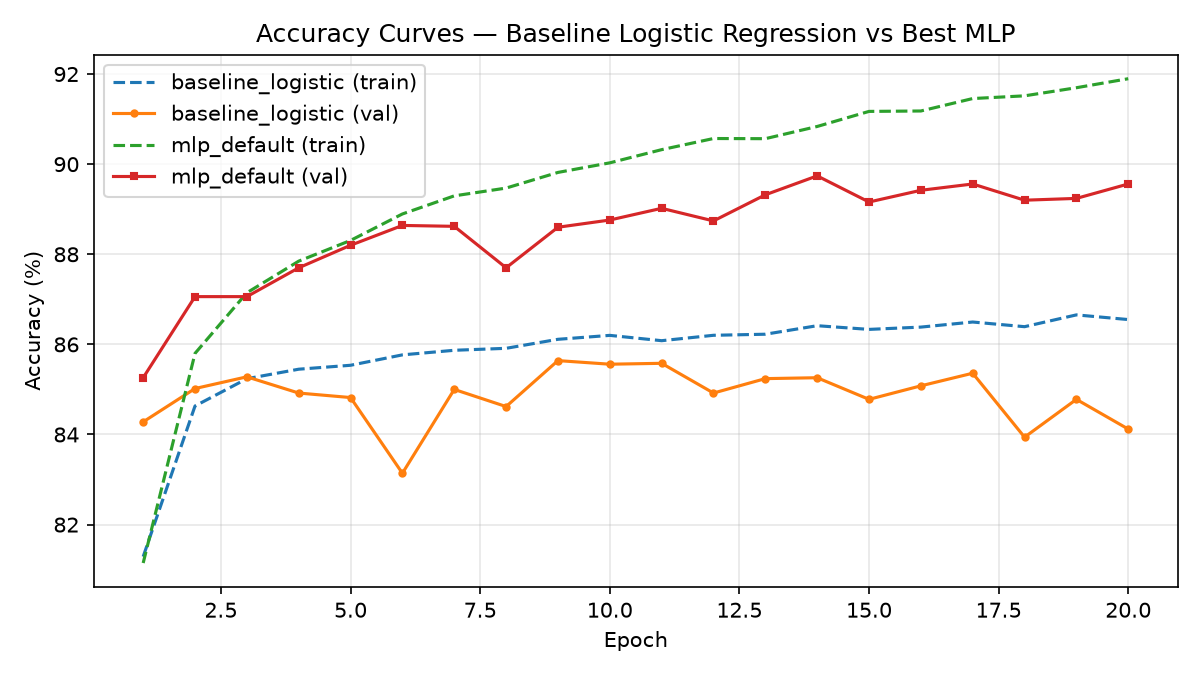

### confusion_matrix_baseline

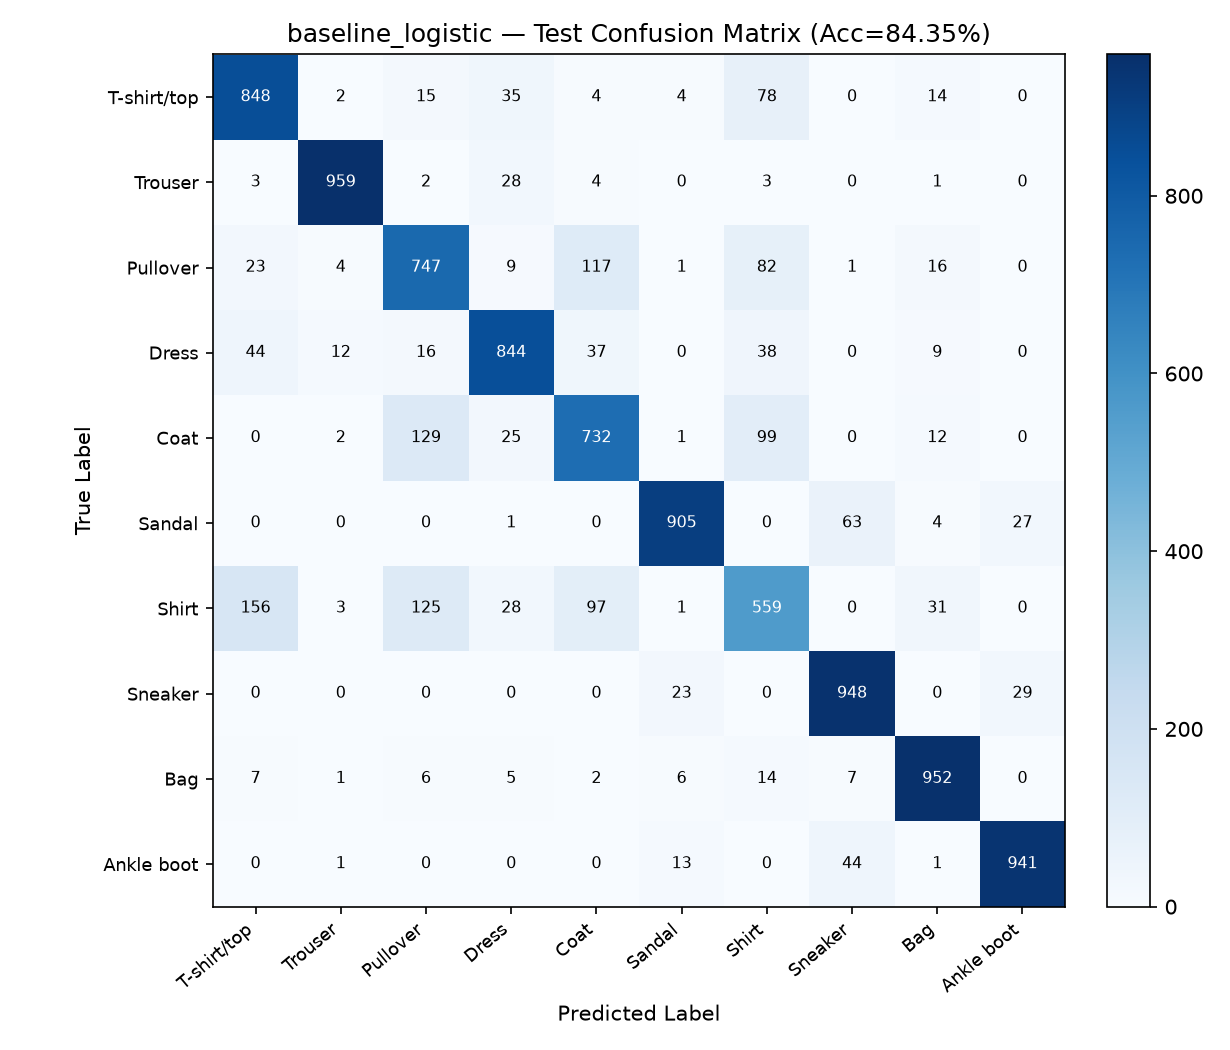

### confusion_matrix_mlp

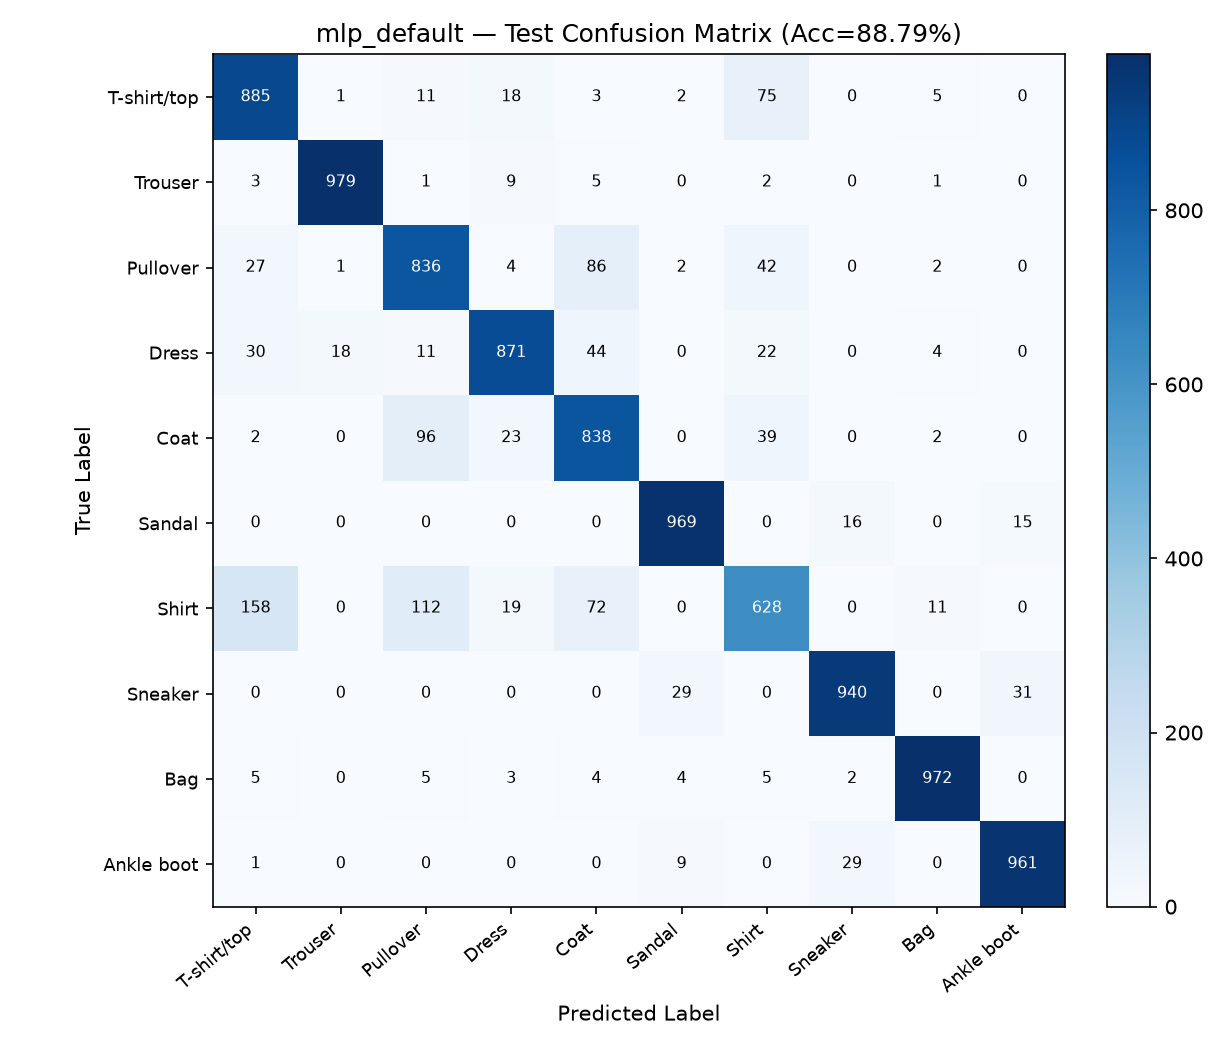

### predicted_vs_actual

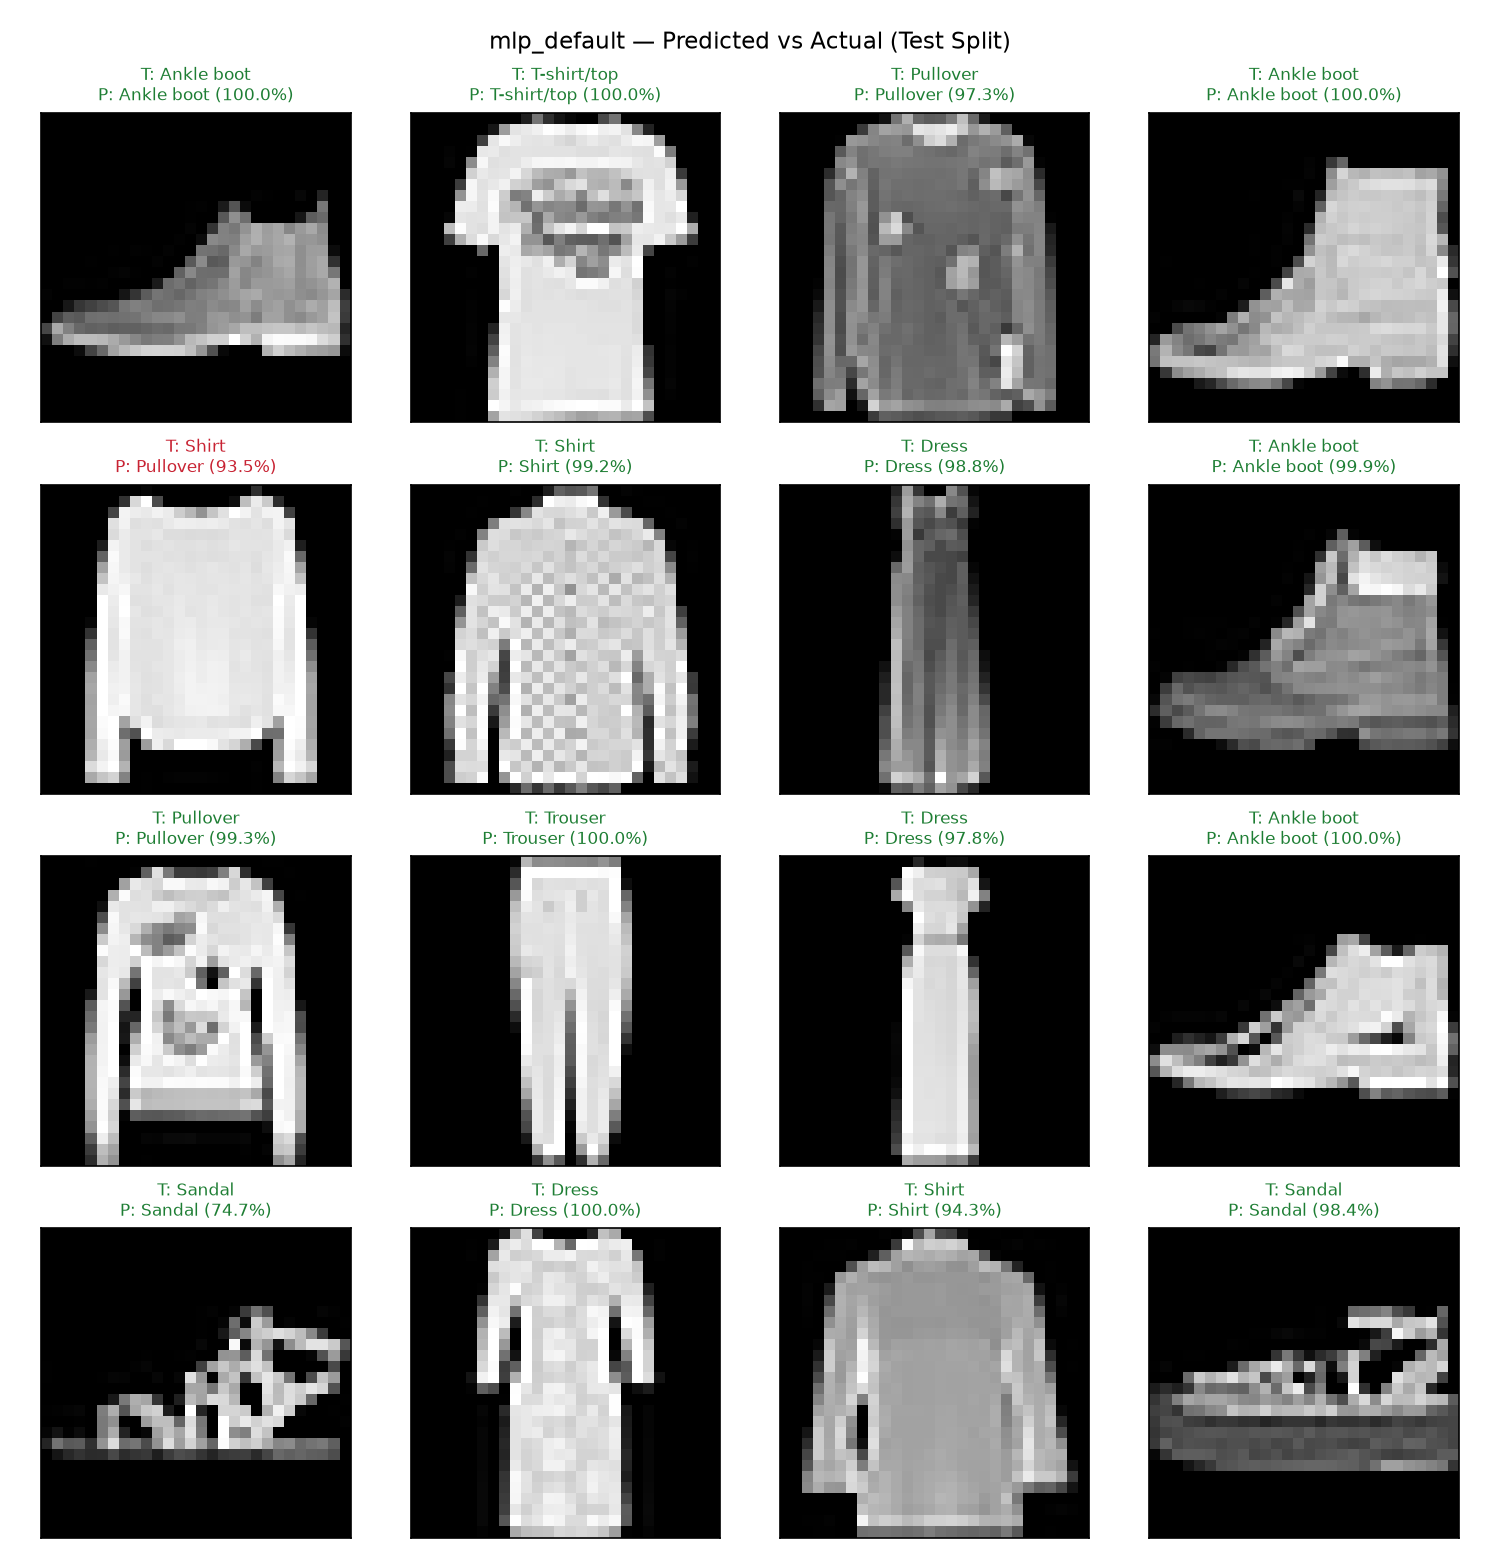

### error_gallery

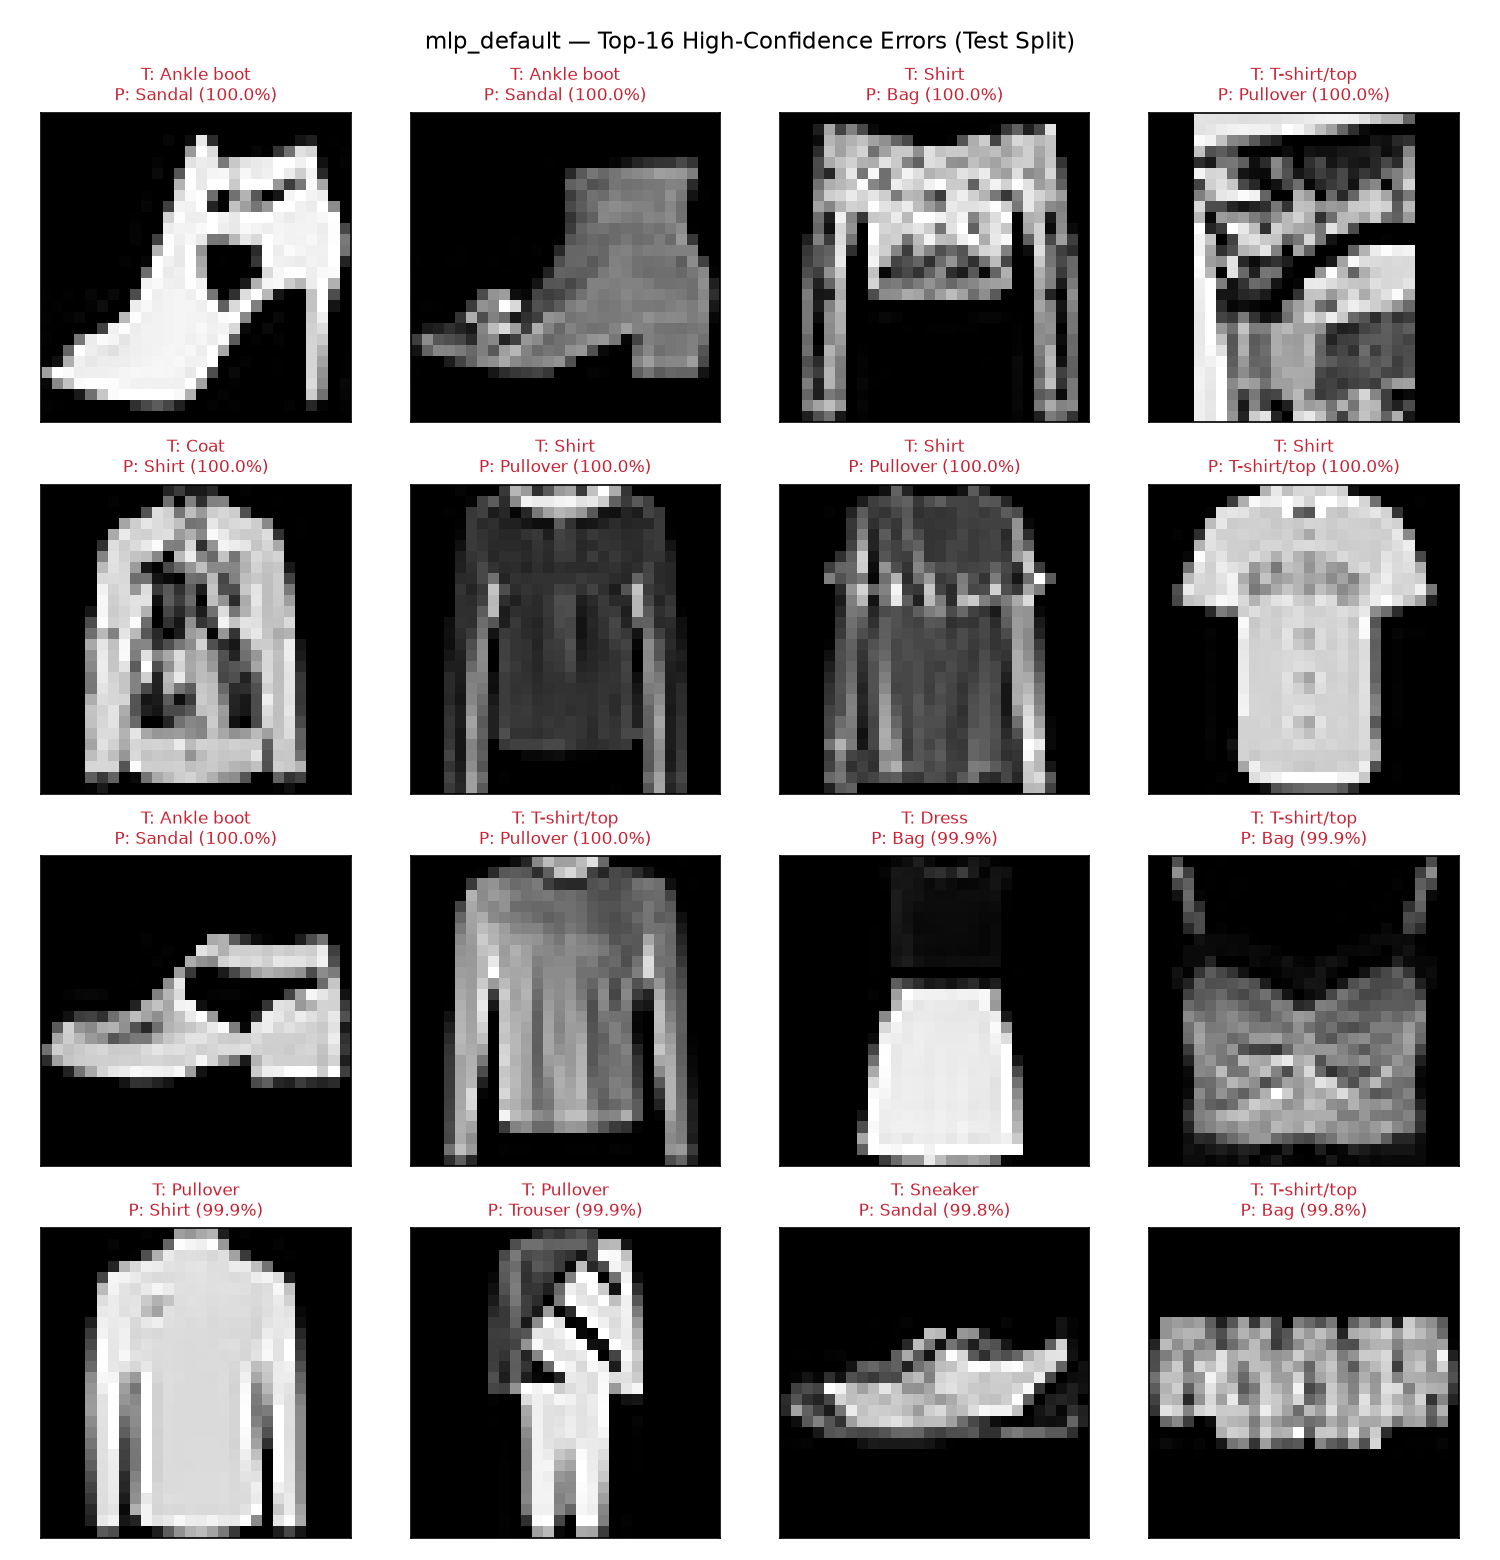

In [6]:
test_json = cfg.EVALUATION_DIR / "test_comparison.json"
err_json = cfg.EVALUATION_DIR / "error_analysis.json"
if not test_json.exists():
    print("Chưa có kết quả Final Test. Hãy chạy: python labs/lab1_v2/evaluate.py")
else:
    test_cmp = json.loads(test_json.read_text(encoding="utf-8"))
    print("=== FINAL TEST COMPARISON (10,000 samples) ===")
    for row in test_cmp["comparison"]:
        print(
            f"{row['run_id']:<18} | params={row['num_parameters']:>7,} | "
            f"test_loss={row['test_loss']:.4f} | test_acc={row['test_accuracy']*100:.2f}% | "
            f"macro_f1={row['test_macro_f1']*100:.2f}% | save_load_ok={row['save_load_passed']}"
        )
    gain = test_cmp["mlp_gain_over_baseline"]
    print(
        f"\nMLP Gain vs Baseline: Acc {gain['accuracy_delta']*100:+.2f} pp | "
        f"Macro-F1 {gain['macro_f1_delta']*100:+.2f} pp | Loss {gain['loss_delta']:+.4f}"
    )
    if err_json.exists():
        err = json.loads(err_json.read_text(encoding="utf-8"))
        print("\nTop-5 Best MLP Confusions:", err["best_mlp_top_confusions"][:5])
    for fig_key in [
        "loss_curves",
        "accuracy_curves",
        "confusion_matrix_baseline",
        "confusion_matrix_mlp",
        "predicted_vs_actual",
        "error_gallery",
    ]:
        fp = test_cmp["figures"].get(fig_key)
        if fp and Path(fp).exists():
            display(Markdown(f"### {fig_key}"))
            display(IPyImage(filename=fp))

In [7]:
if ablation_json.exists():
    abl = json.loads(ablation_json.read_text(encoding="utf-8"))
    winner = abl.get("winning_mlp_run_id")
    ckpt = cfg.RUNS_DIR / winner / "best.pt" if winner else None
    if ckpt and ckpt.exists():
        predictor = FashionPredictor.from_checkpoint(ckpt, device=cfg.DEVICE)
        sample_img, true_lbl = bundle.test_dataset[0]
        pred = predictor.predict_batch(sample_img.unsqueeze(0), top_k=3)[0]
        print(f"Checkpoint: {ckpt.name} ({winner})")
        print(f"True Class: {cfg.CLASS_NAMES[int(true_lbl)]} | Pred: {pred['predicted_class']} ({pred['confidence']*100:.2f}%)")
        print("Top-3     :", pred["top_k"])
        print("Latency BS=1 :", predictor.benchmark_latency(batch_size=1))
        print("Latency BS=32:", predictor.benchmark_latency(batch_size=32))
    else:
        print("Chưa tìm thấy best.pt để chạy live inference.")
else:
    print("Chưa có checkpoint từ CLI training.")

Checkpoint: best.pt (mlp_default)
True Class: Ankle boot | Pred: Ankle boot (99.96%)
Top-3     : [{'class_id': 9, 'class_name': 'Ankle boot', 'probability': 0.9996381998062134}, {'class_id': 5, 'class_name': 'Sandal', 'probability': 0.00033747730776667595}, {'class_id': 7, 'class_name': 'Sneaker', 'probability': 2.4352069885935634e-05}]
Latency BS=1 : {'batch_size': 1.0, 'mean_ms': 0.7932040000741836, 'p95_ms': 1.1033500000849017, 'ms_per_sample': 0.7932040000741836, 'checkpoint_size_kb': 922.2080078125}
Latency BS=32: {'batch_size': 32.0, 'mean_ms': 0.8956499995838385, 'p95_ms': 1.15696999910142, 'ms_per_sample': 0.027989062486994953, 'checkpoint_size_kb': 922.2080078125}
